# Previsão de churn — TechGrow (SaaS)

Objetivo: entender o que leva clientes a cancelar e treinar modelos que apontem quem está em risco.

**Como rodar:** execute as células em ordem (`Shift+Enter`) ou use **Ambiente de execução → Executar tudo**. A primeira célula pede o arquivo `Caso_Pratico_base_churn_saas.csv`.

## 1. Importações e carregamento dos dados

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ARQUIVO = "Caso_Pratico_base_churn_saas.csv"

# No Colab: abre uma caixa para enviar o CSV (se o arquivo ainda não estiver na pasta)
if not os.path.exists(ARQUIVO):
    from google.colab import files
    files.upload()

df = pd.read_csv(ARQUIVO)

Saving Caso_Pratico_base_churn_saas.csv to Caso_Pratico_base_churn_saas.csv


## 2. Exploração inicial

In [2]:
print("Linhas e colunas:", df.shape)
print("\nTipos de dados:")
print(df.dtypes)
print("\nValores nulos por coluna:")
print(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
df.head()

Linhas e colunas: (100, 11)

Tipos de dados:
id_cliente                 object
tempo_contrato_meses        int64
plano                      object
regiao                     object
logins_mes                  int64
tickets_suporte             int64
valor_mensal                int64
inadimplencia               int64
qtd_funcionarios            int64
uso_media_diaria_horas    float64
churn                       int64
dtype: object

Valores nulos por coluna:
id_cliente                0
tempo_contrato_meses      0
plano                     0
regiao                    0
logins_mes                0
tickets_suporte           0
valor_mensal              0
inadimplencia             0
qtd_funcionarios          0
uso_media_diaria_horas    0
churn                     0
dtype: int64

Linhas duplicadas: 0


,id_cliente,tempo_contrato_meses,plano,regiao,logins_mes,tickets_suporte,valor_mensal,inadimplencia,qtd_funcionarios,uso_media_diaria_horas,churn
0,C001,12,Básico,Sudeste,15,2,120,0,3,1.8,0
1,C002,3,Premium,Sul,4,6,350,1,8,0.5,1
2,C003,8,Intermediário,Sudeste,10,1,210,0,5,1.2,0
3,C004,24,Premium,Centro-Oeste,25,0,370,0,12,3.5,0
4,C005,6,Básico,Nordeste,6,4,130,1,2,0.9,1


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tempo_contrato_meses,100.0,9.690,6.107943,1.0,5.0,9.00,13.0,30.0
logins_mes,100.0,13.120,7.413174,2.0,6.0,12.50,19.0,29.0
tickets_suporte,100.0,2.570,2.370931,0.0,1.0,1.50,5.0,8.0
valor_mensal,100.0,204.800,97.125141,100.0,115.0,205.00,240.0,400.0
inadimplencia,100.0,0.420,0.496045,0.0,0.0,0.00,1.0,1.0
qtd_funcionarios,100.0,5.340,3.736849,1.0,2.0,5.00,7.0,15.0
uso_media_diaria_horas,100.0,1.729,1.045461,0.2,0.8,1.65,2.7,4.0
churn,100.0,0.420,0.496045,0.0,0.0,0.00,1.0,1.0


In [4]:
taxa_churn = df["churn"].mean()
print(f"Taxa de churn: {taxa_churn:.0%} ({df['churn'].sum()} de {len(df)} clientes cancelaram)")

Taxa de churn: 42% (42 de 100 clientes cancelaram)


**Leitura:** não há valores nulos nem linhas duplicadas, então não precisa preencher nem remover nada. A base é pequena (100 clientes) e 42% deles cancelaram, uma proporção bem alta e razoavelmente equilibrada entre as classes.

## 3. Visualizações: quem cancela?

In [5]:
numericas = ["tempo_contrato_meses", "logins_mes", "tickets_suporte", "valor_mensal",
             "qtd_funcionarios", "uso_media_diaria_horas"]

# Médias de cada variável para quem ficou (0) e para quem cancelou (1)
df.groupby("churn")[numericas + ["inadimplencia"]].mean().round(2)

,tempo_contrato_meses,logins_mes,tickets_suporte,valor_mensal,qtd_funcionarios,uso_media_diaria_horas,inadimplencia
churn,,,,,,,
0,13.59,18.52,0.76,266.64,7.64,2.47,0.0
1,4.31,5.67,5.07,119.40,2.17,0.70,1.0


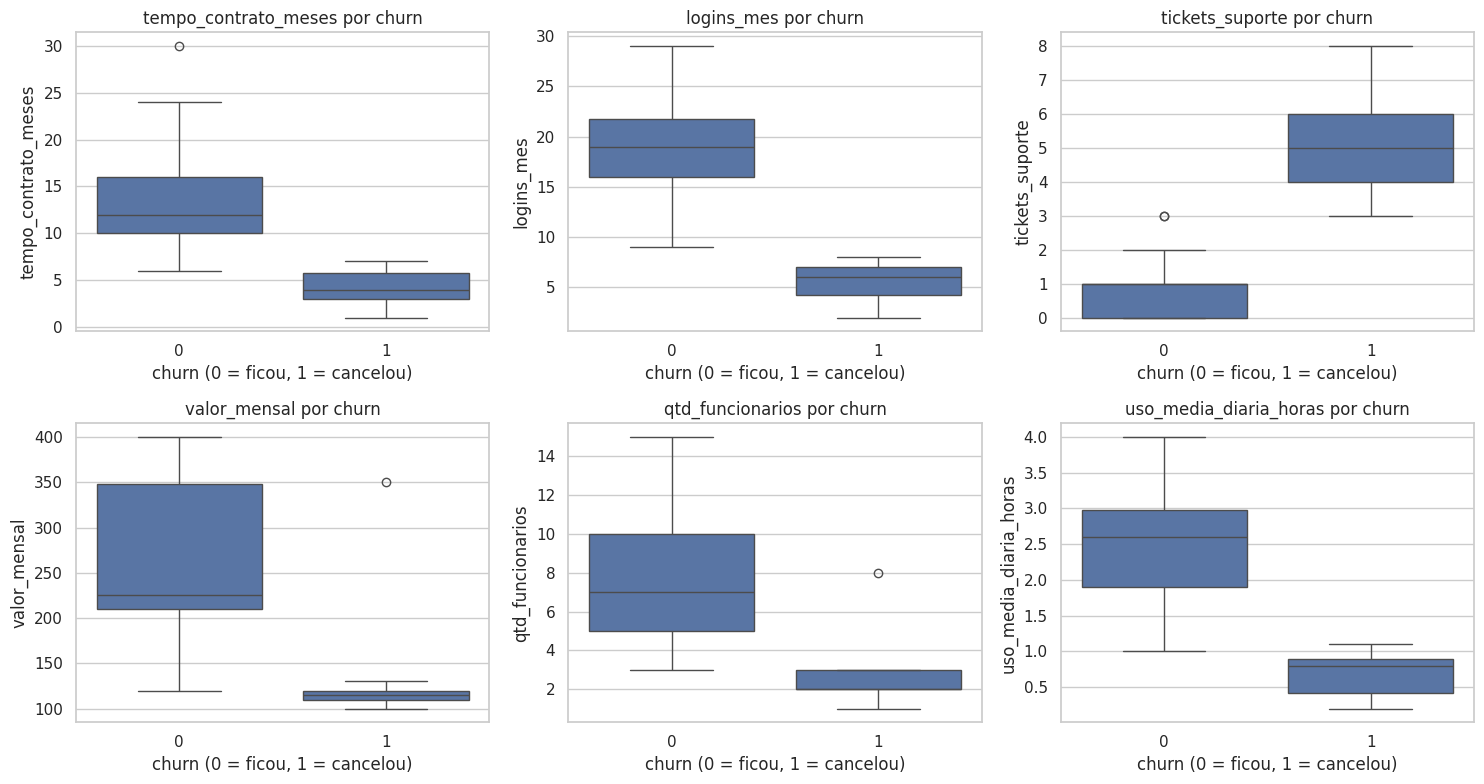

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numericas):
    sns.boxplot(data=df, x="churn", y=col, ax=ax)
    ax.set_title(f"{col} por churn")
    ax.set_xlabel("churn (0 = ficou, 1 = cancelou)")
plt.tight_layout()
plt.show()

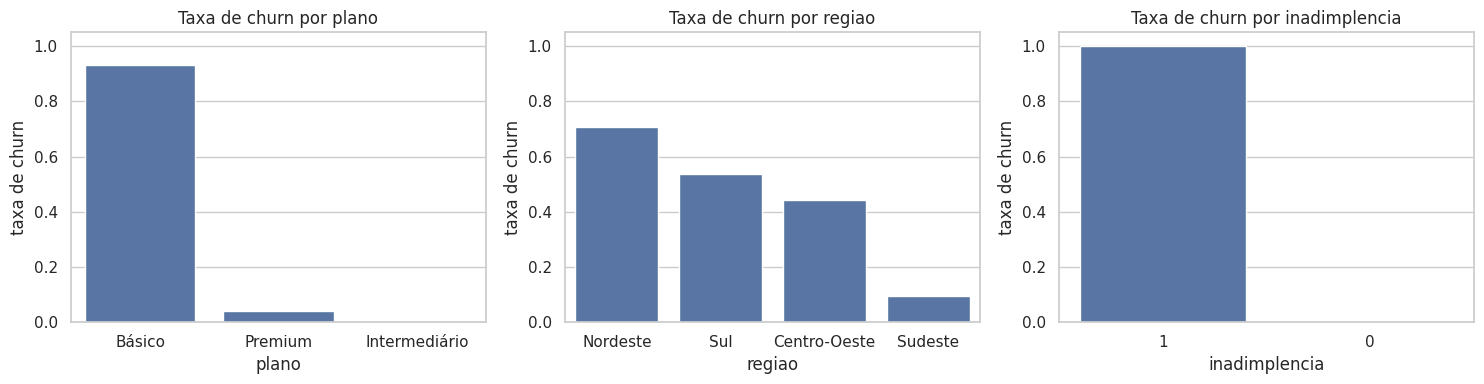

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["plano", "regiao", "inadimplencia"]):
    taxa = df.groupby(col)["churn"].mean().sort_values(ascending=False)
    sns.barplot(x=taxa.index.astype(str), y=taxa.values, ax=ax)
    ax.set_title(f"Taxa de churn por {col}")
    ax.set_ylabel("taxa de churn")
    ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [8]:
print("Churn por plano (contagem):")
print(pd.crosstab(df["plano"], df["churn"]))
print("\nChurn por região (contagem):")
print(pd.crosstab(df["regiao"], df["churn"]))
print("\nPlano por região (contagem):")
print(pd.crosstab(df["regiao"], df["plano"]))

Churn por plano (contagem):
churn           0   1
plano                
Básico          3  41
Intermediário  32   0
Premium        23   1

Churn por região (contagem):
churn          0   1
regiao              
Centro-Oeste  10   8
Nordeste       7  17
Sudeste       29   3
Sul           12  14

Plano por região (contagem):
plano         Básico  Intermediário  Premium
regiao                                      
Centro-Oeste       8              5        5
Nordeste          19              4        1
Sudeste            4             15       13
Sul               13              8        5


**O que os gráficos mostram:**
- Quem cancelou tinha **pouco tempo de contrato** (média de 4,3 meses contra 13,6), **poucos logins** (5,7 contra 18,5 por mês), **muitos tickets de suporte** (5,1 contra 0,8), **valor mensal menor** (R$ 119 contra R$ 267) e **uso diário bem menor** (0,7 h contra 2,5 h).
- O **plano Básico concentra o cancelamento**: 41 dos 44 clientes Básico cancelaram. No Intermediário ninguém cancelou, e no Premium só 1 de 24.
- Por região, o Nordeste (71%) e o Sul (54%) têm mais churn que o Sudeste (9%). Cuidado ao interpretar: o Nordeste e o Sul também têm mais clientes do plano Básico (veja a última tabela), então parte do efeito da região pode ser, na verdade, efeito do plano.
- **Todo cliente inadimplente cancelou** e nenhum adimplente cancelou. Isso é suspeito demais e é tratado na seção 6.

## 4. Correlações e colunas redundantes

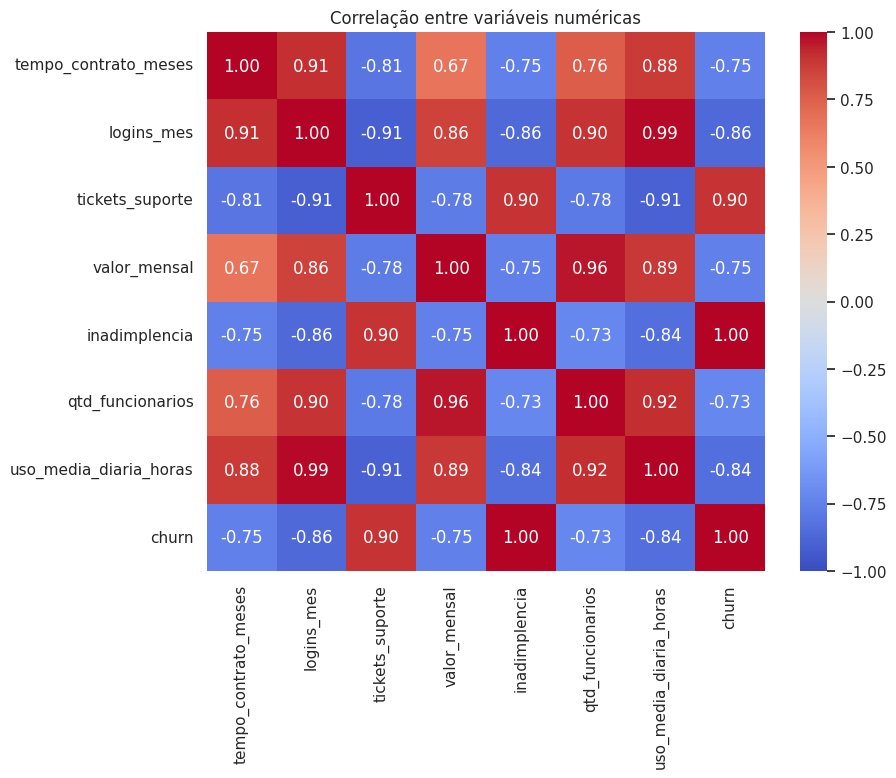

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns="id_cliente").select_dtypes("number").corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação entre variáveis numéricas")
plt.show()

In [10]:
corr = df[numericas].corr()
print("logins_mes x uso_media_diaria_horas:", round(corr.loc["logins_mes", "uso_media_diaria_horas"], 2))
print("valor_mensal x qtd_funcionarios:    ", round(corr.loc["valor_mensal", "qtd_funcionarios"], 2))
print("inadimplencia x churn:              ", round(df["inadimplencia"].corr(df["churn"]), 2))

logins_mes x uso_media_diaria_horas: 0.99
valor_mensal x qtd_funcionarios:     0.96
inadimplencia x churn:               1.0


**Decisões:**
- `id_cliente` é só um identificador, não ajuda a prever nada: **removida**.
- `uso_media_diaria_horas` tem correlação de 0,99 com `logins_mes` (praticamente a mesma informação): **removida**, ficando só os logins.
- `qtd_funcionarios` tem correlação de 0,96 com `valor_mensal`: **removida**, ficando só o valor mensal.
- `inadimplencia` tem correlação **1,00** com o churn. Em vez de decidir sozinho, o notebook treina os modelos **com** e **sem** essa coluna e compara (seção 6).

## 5. Preparação dos dados e divisão treino/teste (70/30)

In [11]:
dados = df.drop(columns=["id_cliente", "uso_media_diaria_horas", "qtd_funcionarios"]).copy()

# plano tem ordem natural (Básico < Intermediário < Premium): encoding ordinal
dados["plano"] = dados["plano"].map({"Básico": 0, "Intermediário": 1, "Premium": 2})

# região não tem ordem: one-hot encoding (drop_first evita coluna redundante)
dados = pd.get_dummies(dados, columns=["regiao"], drop_first=True, dtype=int)

print("Colunas após o encoding:", list(dados.columns))
dados.head()

Colunas após o encoding: ['tempo_contrato_meses', 'plano', 'logins_mes', 'tickets_suporte', 'valor_mensal', 'inadimplencia', 'churn', 'regiao_Nordeste', 'regiao_Sudeste', 'regiao_Sul']


,tempo_contrato_meses,plano,logins_mes,tickets_suporte,valor_mensal,inadimplencia,churn,regiao_Nordeste,regiao_Sudeste,regiao_Sul
0,12,0,15,2,120,0,0,0,1,0
1,3,2,4,6,350,1,1,0,0,1
2,8,1,10,1,210,0,0,0,1,0
3,24,2,25,0,370,0,0,0,0,0
4,6,0,6,4,130,1,1,1,0,0


In [12]:
def dividir(dados, remover=()):
    X = dados.drop(columns=["churn", *remover])
    y = dados["churn"]
    # stratify mantém a mesma proporção de churn no treino e no teste
    return train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

X_train, X_test, y_train, y_test = dividir(dados)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Churn no treino:", round(y_train.mean(), 2), "| Churn no teste:", round(y_test.mean(), 2))

Treino: (70, 9) | Teste: (30, 9)
Churn no treino: 0.41 | Churn no teste: 0.43


A normalização (`StandardScaler`) só é necessária na Regressão Logística, que é sensível à escala das variáveis. Ela vai dentro de um `Pipeline` junto com o modelo, assim o escalonamento é aprendido só com os dados de treino. Random Forest e XGBoost não precisam disso.

## 6. Treino e avaliação dos modelos

In [13]:
def criar_modelos():
    return {
        "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
        "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                                 random_state=42, eval_metric="logloss"),
    }

def treinar_e_avaliar(X_train, X_test, y_train, y_test, titulo):
    modelos = criar_modelos()
    linhas, previsoes, probas = [], {}, {}
    for nome, modelo in modelos.items():
        modelo.fit(X_train, y_train)
        pred = modelo.predict(X_test)
        proba = modelo.predict_proba(X_test)[:, 1]
        previsoes[nome], probas[nome] = pred, proba
        linhas.append({
            "modelo": nome,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1-score": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba),
        })
    tabela = pd.DataFrame(linhas).set_index("modelo").round(3)

    # matriz de confusão de cada modelo
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (nome, pred) in zip(axes, previsoes.items()):
        ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["ficou", "cancelou"]).plot(ax=ax, colorbar=False)
        ax.set_title(nome)
    fig.suptitle(f"Matrizes de confusão - {titulo}")
    plt.tight_layout(); plt.show()

    # curva ROC dos três modelos no mesmo gráfico
    plt.figure(figsize=(6, 5))
    for nome, proba in probas.items():
        fpr, tpr, _ = roc_curve(y_test, proba)
        plt.plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc_score(y_test, proba):.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="aleatório")
    plt.xlabel("Taxa de falsos positivos"); plt.ylabel("Taxa de verdadeiros positivos")
    plt.title(f"Curva ROC - {titulo}"); plt.legend(); plt.show()

    return tabela, modelos

### Cenário A: todas as variáveis (incluindo `inadimplencia`)

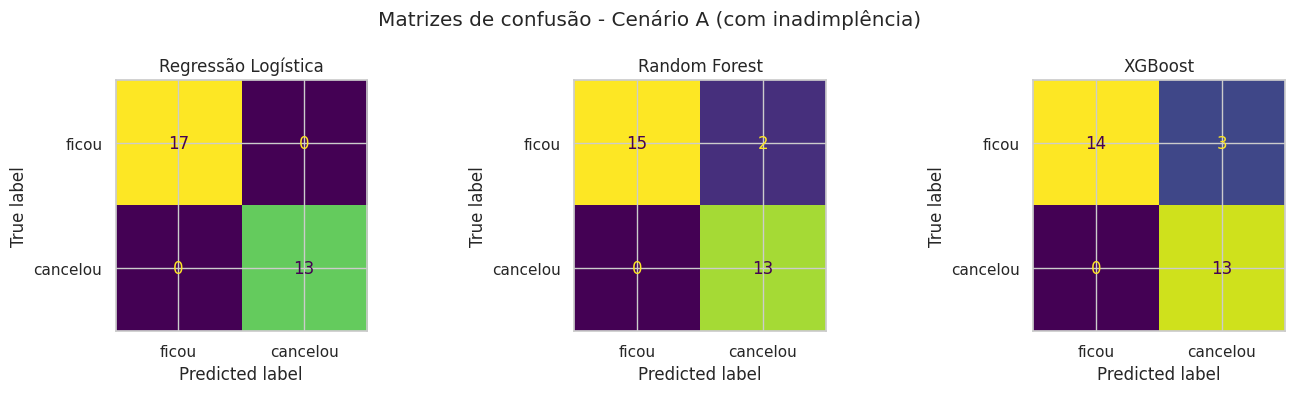

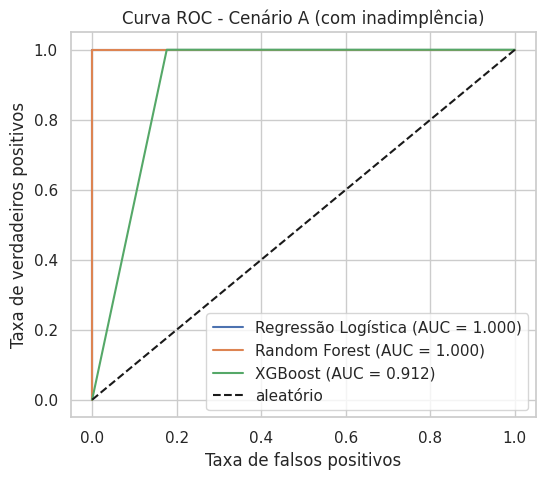

,accuracy,precision,recall,f1-score,roc_auc
modelo,,,,,
Regressão Logística,1.000,1.000,1.0,1.000,1.000
Random Forest,0.933,0.867,1.0,0.929,1.000
XGBoost,0.900,0.812,1.0,0.897,0.912


In [14]:
tabela_A, modelos_A = treinar_e_avaliar(X_train, X_test, y_train, y_test, "Cenário A (com inadimplência)")
tabela_A

### Cenário B: sem `inadimplencia`

Como todo inadimplente cancelou, essa coluna sozinha "entrega" a resposta. Na prática, a inadimplência pode até ser **consequência** do cancelamento (o cliente para de pagar quando decide sair), e nesse caso ela não serviria para avisar com antecedência. Por isso o cenário B mostra o desempenho do modelo usando só os sinais de comportamento e perfil.

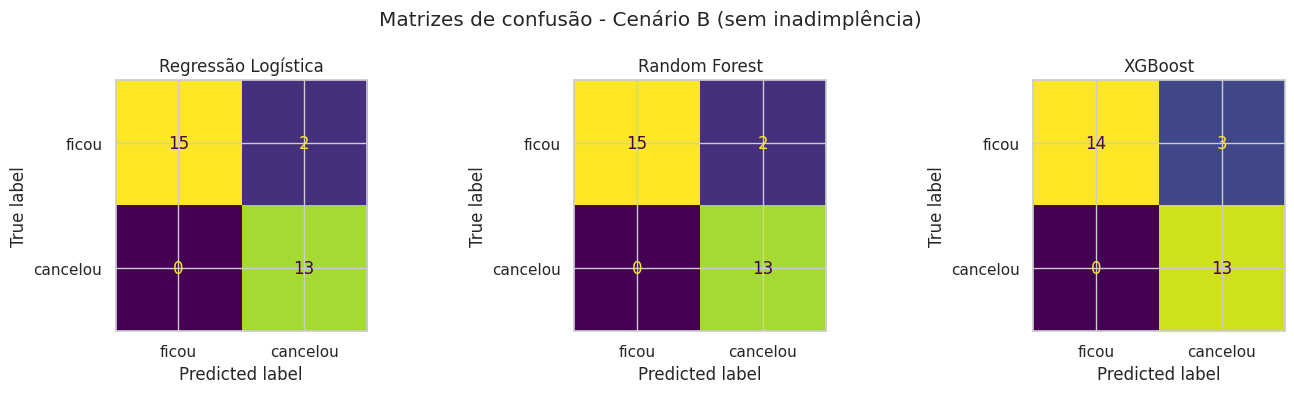

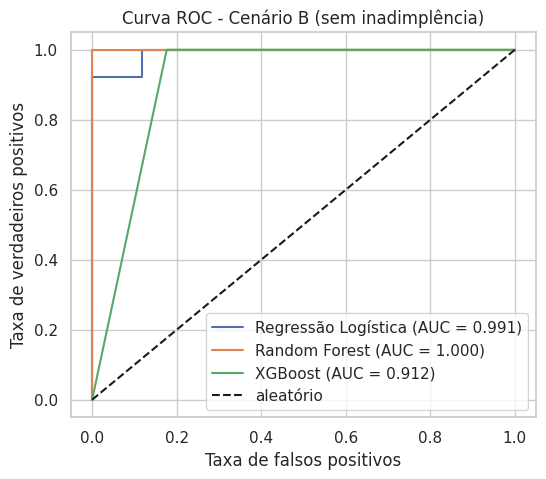

,accuracy,precision,recall,f1-score,roc_auc
modelo,,,,,
Regressão Logística,0.933,0.867,1.0,0.929,0.991
Random Forest,0.933,0.867,1.0,0.929,1.000
XGBoost,0.900,0.812,1.0,0.897,0.912


In [15]:
X_train_B, X_test_B, y_train_B, y_test_B = dividir(dados, remover=["inadimplencia"])
tabela_B, modelos_B = treinar_e_avaliar(X_train_B, X_test_B, y_train_B, y_test_B, "Cenário B (sem inadimplência)")
tabela_B

### Conferindo se o resultado é estável (validação cruzada)

Com 100 clientes, o conjunto de teste tem só 30 linhas: cada erro muda as métricas em mais de 3 pontos percentuais. A validação cruzada de 5 partes usa todos os dados para testar e dá uma ideia mais confiável.

In [16]:
X_B = dados.drop(columns=["churn", "inadimplencia"])
y_all = dados["churn"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultado_cv = {}
for nome, modelo in criar_modelos().items():
    scores = cross_val_score(modelo, X_B, y_all, cv=cv, scoring="roc_auc")
    resultado_cv[nome] = {"roc_auc médio": scores.mean(), "desvio": scores.std()}
pd.DataFrame(resultado_cv).T.round(3)

,roc_auc médio,desvio
Regressão Logística,1.0,0.0
Random Forest,1.0,0.0
XGBoost,1.0,0.0


## 7. Quais variáveis mais impactam o churn?

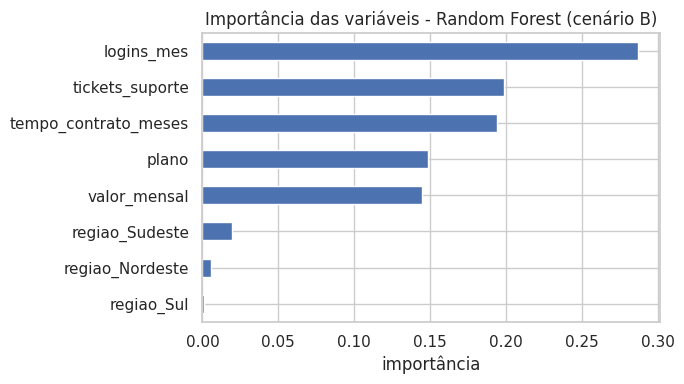

,0
logins_mes,0.287
tickets_suporte,0.198
tempo_contrato_meses,0.194
plano,0.149
valor_mensal,0.145
regiao_Sudeste,0.019
regiao_Nordeste,0.005
regiao_Sul,0.001


In [17]:
rf_B = modelos_B["Random Forest"]
importancia = pd.Series(rf_B.feature_importances_, index=X_train_B.columns).sort_values()

plt.figure(figsize=(7, 4))
importancia.plot(kind="barh")
plt.title("Importância das variáveis - Random Forest (cenário B)")
plt.xlabel("importância")
plt.tight_layout(); plt.show()
importancia.sort_values(ascending=False).round(3)

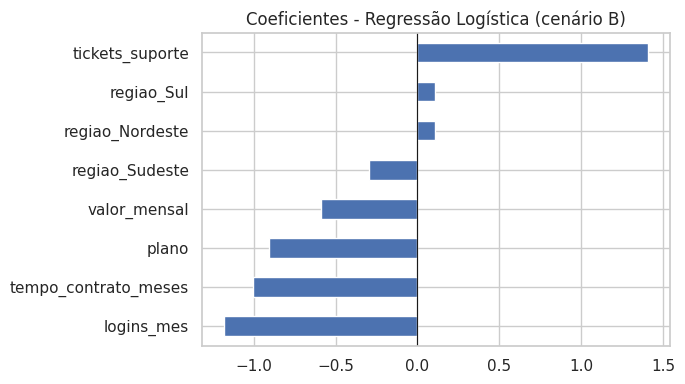

,0
logins_mes,-1.18
tempo_contrato_meses,-1.00
plano,-0.91
valor_mensal,-0.59
regiao_Sudeste,-0.30
regiao_Nordeste,0.11
regiao_Sul,0.11
tickets_suporte,1.41


In [18]:
# Regressão Logística: o sinal do coeficiente mostra a direção do efeito
# (variáveis já padronizadas, então os tamanhos são comparáveis)
reg_B = modelos_B["Regressão Logística"].named_steps["logisticregression"]
coef = pd.Series(reg_B.coef_[0], index=X_train_B.columns).sort_values()
plt.figure(figsize=(7, 4))
coef.plot(kind="barh")
plt.title("Coeficientes - Regressão Logística (cenário B)")
plt.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()
coef.round(2)

In [19]:
xgb_B = modelos_B["XGBoost"]
imp_xgb = pd.Series(xgb_B.feature_importances_, index=X_train_B.columns).sort_values(ascending=False)
imp_xgb.round(3)

,0
logins_mes,1.0
tempo_contrato_meses,0.0
plano,0.0
tickets_suporte,0.0
valor_mensal,0.0
regiao_Nordeste,0.0
regiao_Sudeste,0.0
regiao_Sul,0.0


In [20]:
# Resumo automático do cenário B (use estes números na interpretação abaixo)
for nome, linha in tabela_B.iterrows():
    print(f"{nome}: accuracy={linha['accuracy']:.2f} | precision={linha['precision']:.2f} | "
          f"recall={linha['recall']:.2f} | f1={linha['f1-score']:.2f} | roc_auc={linha['roc_auc']:.2f}")


Regressão Logística: accuracy=0.93 | precision=0.87 | recall=1.00 | f1=0.93 | roc_auc=0.99
Random Forest: accuracy=0.93 | precision=0.87 | recall=1.00 | f1=0.93 | roc_auc=1.00
XGBoost: accuracy=0.90 | precision=0.81 | recall=1.00 | f1=0.90 | roc_auc=0.91


## 8. Interpretação e recomendações

**Quais variáveis mais impactam o churn?**
Nos modelos sem a inadimplência (cenário B), os sinais mais fortes são o **número de logins por mês**, os **tickets de suporte** e o **tempo de contrato**, seguidos de **plano** e **valor mensal**. A região pesa pouco depois que o plano é considerado, o que reforça que a diferença regional vista nos gráficos vem em boa parte da concentração de planos Básico no Nordeste e no Sul. Os valores exatos de cada modelo aparecem nos gráficos da seção 7 O XGBoost foi diferente: concentrou toda a importância em `logins_mes` e deixou as demais perto de zero, porque só esse sinal já bastou para separar os dados de treino. Isso não quer dizer que as outras variáveis não importem, só que, para esse modelo, elas ficaram redundantes.

**O modelo identifica bem quem vai cancelar?**
Nos testes, a Regressão Logística e o Random Forest acertaram todos os clientes que cancelaram (recall = 1,0), errando apenas por alarme falso em alguns que ficaram (precision menor que 1). O XGBoost também acertou todos os cancelamentos (recall = 1,0), mas teve 3 alarmes falsos (precision = 0,81) e ROC AUC de 0,91 no teste, abaixo dos outros dois. Como na validação cruzada ele chegou a 1,00, essa diferença parece vir do teste pequeno e não de um modelo pior. Para o negócio, esse perfil é bom: é melhor abordar um cliente que não ia sair do que deixar passar um que ia.
Mas há três ressalvas importantes:
1. A base tem só 100 clientes e o teste tem 30, então cada erro pesa mais de 3 pontos nas métricas (dois alarmes falsos já levam a precision a 0,87). Na validação cruzada (seção 6), os três modelos tiveram ROC AUC médio de 1,00 (desvio 0,00) mesmo sem a inadimplência, o que confirma que as classes são muito separáveis. Os resultados são um bom indício, não uma garantia.
2. Os dados são muito "separáveis" (as classes quase não se misturam), o que é incomum em dados reais. Em produção, esperar métricas mais baixas.
3. A `inadimplencia` coincide 100% com o churn. Se ela acontece **depois** da decisão de sair, usá-la no modelo seria vazamento de informação (o modelo "colaria" a resposta). Por isso o cenário B é o mais honesto para uso real.

**Ações sugeridas ao time de produto:**
- **Criar um alerta de risco** com os sinais que mais pesam: poucos logins no mês e aumento de tickets de suporte. Quem cruzar esses limites entra numa lista para contato do time de sucesso do cliente.
- **Reforçar os primeiros meses**: quem cancelou ficou em média 4 meses (o máximo foi 7), e nenhum cliente com mais de 7 meses cancelou. Um onboarding mais próximo até o 6º mês ataca a janela de maior risco.
- **Revisar o plano Básico**: 93% de churn. Vale investigar se ele entrega valor suficiente, testar ofertas de upgrade para o Intermediário (onde ninguém cancelou) e ajustar o que o plano inclui.
- **Olhar suporte com cuidado**: muitos tickets andam junto com o cancelamento. Tratar rápido os tickets de clientes novos pode evitar a saída.
- **Cobrança**: abordar a inadimplência cedo, com renegociação, em vez de esperar o cliente sair.
- **Investigar Nordeste e Sul** (mais churn), separando o que é efeito do plano do que é efeito da região (atendimento, preço, concorrência).
- **Coletar mais dados** e repetir o estudo para confirmar esses padrões.